# Stage 1 ? XGBoost

The first stage of the fraud pipeline. XGBoost scores every transaction; transactions above a **flagging threshold** go on to the agent in stage 2 (`agent/`), which confirms or clears each flag.

Input: `data/processed/fraudTrain_features.csv`, `data/processed/fraudTest_features.csv` (from `preprocessing.ipynb`)

Output, for the agent pipeline:
- `data/processed/flagged_val.csv`, `flagged_test.csv`: the flagged cases, **without labels**
- `data/processed/scores_val.csv`, `scores_test.csv`: every transaction's score and label, used only for evaluation
- `data/processed/xgb_thresholds.json`: the two thresholds
- `data/processed/xgb_model.json`: the final model

This notebook covers:
1. Loading the data (all 110 features)
2. Tuning on validation
3. Model evaluation
4. The two thresholds
5. The final model on the test set
6. Feature importance
7. Exporting the flagged cases


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

pd.set_option("display.max_columns", None)
%matplotlib inline

DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"
SEED = 4102

# Share of validation fraud the flagging threshold must catch. A group decision (see the plan):
# higher means fewer missed frauds but more cases, and more cost, for the agent.
RECALL_TARGET = 0.98

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 1. Load data

Same train (fit) / validation / test split as `logistic_regression.ipynb`: the first 80% of `fraudTrain` for fitting, the last 20% (Mar–Jun 2020) for tuning and thresholds, and `fraudTest` (Jun–Dec 2020) for the final evaluation.

In [2]:
train = pd.read_csv(PROCESSED_DIR / "fraudTrain_features.csv")
test = pd.read_csv(PROCESSED_DIR / "fraudTest_features.csv")

X_train_full = train.drop(columns=["is_fraud"]).astype("float32")
y_train_full = train["is_fraud"]
X_test = test.drop(columns=["is_fraud"]).astype("float32")
y_test = test["is_fraud"]

cut = int(len(X_train_full) * 0.8)
X_tr, y_tr = X_train_full.iloc[:cut], y_train_full.iloc[:cut]
X_val, y_val = X_train_full.iloc[cut:], y_train_full.iloc[cut:]

# Use all 110 features: transaction, KYC and behavioural.
cols = list(X_train_full.columns)

# Weight each fraud case by (legitimate / fraud) in the fit rows, so the rare class isn't ignored
scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"fit {len(X_tr):,} | validation {len(X_val):,} | test {len(X_test):,} | features {len(cols):,} | scale_pos_weight {scale_pos_weight:.0f}")


fit 1,037,340 | validation 259,335 | test 555,719 | features 110 | scale_pos_weight 173


## 2. Tuning on validation

XGBoost builds trees one after another, each correcting the errors of the ones before. Settings:

- **Tree depth** is tuned (4, 6 or 8 levels). Deeper trees learn more complex combinations but overfit more easily.
- **Number of trees** is set by **early stopping**: training stops once validation PR-AUC hasn't improved for 50 rounds, and the best round is kept.
- Learning rate 0.1, and each tree sees a random 80% of rows and 80% of features, which reduces overfitting.

Tuning uses all 110 features.


In [3]:
def make_model(n_estimators=2000, early_stopping=True, **params):
    return xgb.XGBClassifier(
        n_estimators=n_estimators,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        eval_metric="aucpr",
        early_stopping_rounds=50 if early_stopping else None,
        scale_pos_weight=scale_pos_weight,
        n_jobs=-1,
        random_state=SEED,
        **params,
    )


search, val_models = [], {}
for depth in [4, 6, 8]:
    model = make_model(max_depth=depth).fit(X_tr[cols], y_tr, eval_set=[(X_val[cols], y_val)], verbose=False)
    proba = model.predict_proba(X_val[cols])[:, 1]
    val_models[depth] = model
    search.append({"max_depth": depth, "trees": model.best_iteration + 1,
                   "val PR-AUC": average_precision_score(y_val, proba), "val ROC-AUC": roc_auc_score(y_val, proba)})

search = pd.DataFrame(search).set_index("max_depth")
best_depth = int(search["val PR-AUC"].idxmax())
print(f"Best depth: {best_depth}")
search.round(4)


Best depth: 8


,trees,val PR-AUC,val ROC-AUC
max_depth,,,
4,823,0.9730,0.9995
6,601,0.9787,0.9995
8,453,0.9796,0.9996


## 3. Model evaluation

The single XGBoost model uses all 110 features. Its standalone threshold maximises F1 on validation data.


In [4]:
def best_f1_threshold(y, proba):
    precision, recall, thresholds = precision_recall_curve(y, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1)])


def scores_at(y, proba, threshold):
    alert = proba >= threshold
    caught = int((alert & (y == 1)).sum())
    return {"alerts": int(alert.sum()), "frauds caught": caught, "false alarms": int(alert.sum()) - caught,
            "precision": caught / max(int(alert.sum()), 1), "recall": caught / int((y == 1).sum())}


val_model = val_models[best_depth]
val_proba = val_model.predict_proba(X_val[cols])[:, 1]
trees = val_model.best_iteration + 1
standalone = best_f1_threshold(y_val, val_proba)

final = make_model(n_estimators=trees, early_stopping=False, max_depth=best_depth).fit(X_train_full[cols], y_train_full)
test_proba = final.predict_proba(X_test[cols])[:, 1]
fitted = {"val_model": val_model, "final": final, "val_proba": val_proba,
          "test_proba": test_proba, "standalone": standalone, "trees": trees}


## 4. The two thresholds

Both thresholds are set on validation:

- **Standalone threshold** (best F1): "XGBoost alone".
- **Flagging threshold**: the highest threshold that still catches `RECALL_TARGET` of validation fraud. Every transaction at or above it goes to the agent.

The gap between them is the agent's room to add value: it reviews more cases than XGBoost alone would alert on.


In [5]:
f = fitted
val_proba, test_proba = f["val_proba"], f["test_proba"]
standalone = f["standalone"]

precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
flag = float(thresholds[np.where(recall[:-1] >= RECALL_TARGET)[0].max()])
assert flag <= standalone

pd.DataFrame({
    f"standalone ({standalone:.3f})": scores_at(y_val, val_proba, standalone),
    f"flagging ({flag:.3f})": scores_at(y_val, val_proba, flag),
}).T.round(3)


,alerts,frauds caught,false alarms,precision,recall
standalone (0.822),1450.0,1413.0,37.0,0.974,0.919
flagging (0.011),2233.0,1508.0,725.0,0.675,0.980


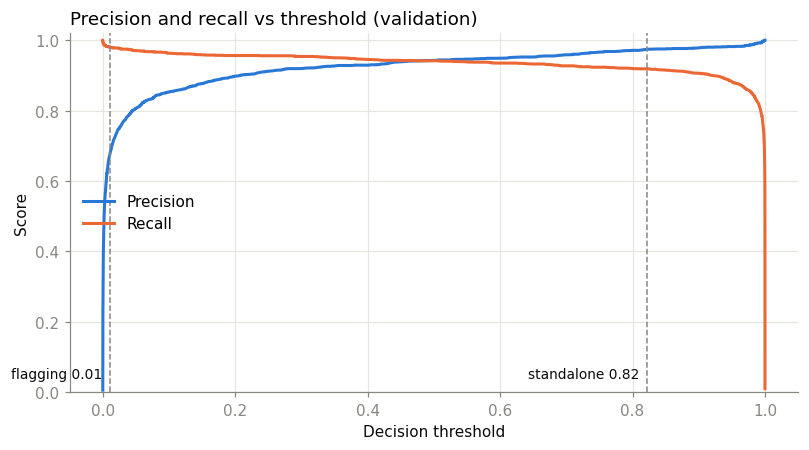

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(thresholds, precision[:-1], color=BLUE, label="Precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, label="Recall")
for t, label in [(flag, f"flagging {flag:.2f}"), (standalone, f"standalone {standalone:.2f}")]:
    ax.axvline(t, color=MUTED, linestyle="--", linewidth=1)
    ax.annotate(label, (t, 0.04), xytext=(-5, 0), textcoords="offset points", ha="right", color=INK, fontsize=9)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.set_title("Precision and recall vs threshold (validation)", loc="left")
ax.legend(frameon=False, loc="center left")
plt.tight_layout()
plt.show()

## Validation model comparison

| Model | Validation PR-AUC |
|---|---:|
| Logistic Regression | 0.420 |
| Random Forest | 0.942 |
| XGBoost | 0.980 |

XGBoost is selected as the Stage 1 model because it achieves the highest validation PR-AUC. PR-AUC is particularly appropriate for this highly imbalanced fraud-detection problem because it measures the precision-recall trade-off for the rare fraud class. XGBoost also provides the strongest ranking of suspicious transactions, which supports the high-recall flagging threshold used before Stage 2 agent review. The test set is not used for this model selection.

## 5. The final model on the test set

The final model was refit on all of `fraudTrain`; both thresholds come from validation unchanged.

In [7]:
print(f"Test PR-AUC {average_precision_score(y_test, test_proba):.4f} | ROC-AUC {roc_auc_score(y_test, test_proba):.4f}")
pd.DataFrame({
    f"standalone ({standalone:.3f})": scores_at(y_test, test_proba, standalone),
    f"flagging ({flag:.3f})": scores_at(y_test, test_proba, flag),
}).T.round(3)

Test PR-AUC 0.9691 | ROC-AUC 0.9991


,alerts,frauds caught,false alarms,precision,recall
standalone (0.822),1972.0,1897.0,75.0,0.962,0.884
flagging (0.011),3456.0,2088.0,1368.0,0.604,0.973


## 6. Feature importance

Total gain: how much each feature improved the model's fit across all the splits that use it. Unlike logistic regression coefficients, importance has no sign: it says how much a feature matters, not in which direction.

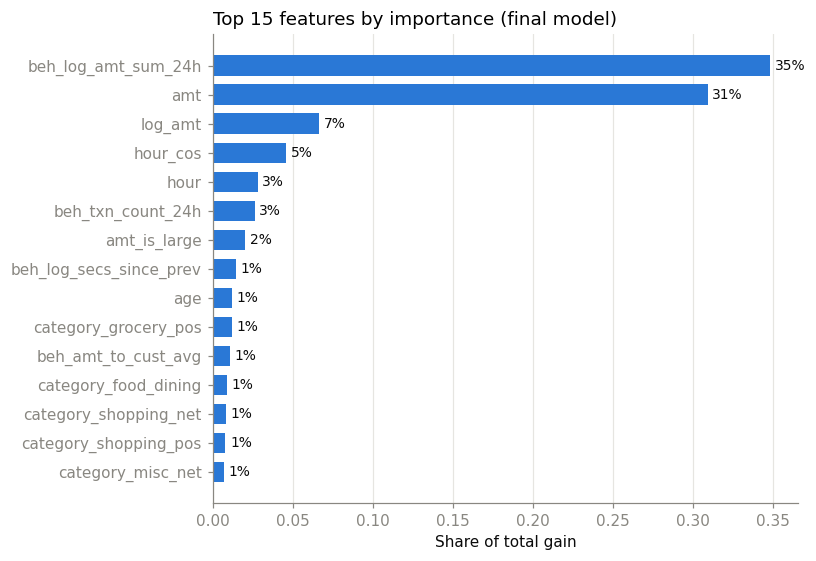

In [8]:
gain = pd.Series(f["final"].get_booster().get_score(importance_type="total_gain")).sort_values()
top = gain.tail(15) / gain.sum()

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in top.values], padding=3, color=INK, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of total gain")
ax.set_title("Top 15 features by importance (final model)", loc="left")
plt.tight_layout()
plt.show()

## 7. Export for the agent pipeline

- **Validation cases** are scored by the model fit on the first 80% only, the same model that set the thresholds, so they are genuinely out-of-sample.
- **Test cases** are scored by the final model.

The processed feature files keep the raw files' row order, so each row is matched back to its raw transaction by position (checked below against the amount). Flagged-case files carry no label. Labels go only into the scores files, which the pipeline reads for evaluation, never for review. As in `agent/data.py`, the simulator's `fraud_` prefix is stripped from merchant names.

In [9]:
CASE_COLUMNS = ["trans_num", "cc_num", "trans_date_trans_time", "amt", "merchant", "category"]
raw_train = pd.read_csv(DATA_DIR / "fraudTrain.csv", usecols=CASE_COLUMNS)
raw_test = pd.read_csv(DATA_DIR / "fraudTest.csv", usecols=CASE_COLUMNS)
assert np.allclose(raw_train["amt"].to_numpy(), X_train_full["amt"].to_numpy())
assert np.allclose(raw_test["amt"].to_numpy(), X_test["amt"].to_numpy())

exports = {
    "val": (raw_train.iloc[cut:].reset_index(drop=True), f["val_model"].predict_proba(X_val[cols])[:, 1], y_val),
    "test": (raw_test, test_proba, y_test),
}
for split, (raw, proba, y) in exports.items():
    cases = raw.assign(merchant=raw["merchant"].str.removeprefix("fraud_"), xgb_score=proba)
    pd.DataFrame({"trans_num": cases["trans_num"], "xgb_score": proba, "is_fraud": y.to_numpy()}).to_csv(
        PROCESSED_DIR / f"scores_{split}.csv", index=False)
    flagged = cases[cases["xgb_score"] >= flag]
    flagged.to_csv(PROCESSED_DIR / f"flagged_{split}.csv", index=False)
    caught = int(y.to_numpy()[proba >= flag].sum())
    print(f"{split}: {len(flagged):,} flagged of {len(cases):,} ({caught:,} of {int(y.sum()):,} frauds among them)")

(PROCESSED_DIR / "xgb_thresholds.json").write_text(json.dumps({
    "standalone": standalone,
    "flag": flag,
    "recall_target": RECALL_TARGET,
    "feature_set": "all 110 (transaction + KYC + behavioural)",
    "max_depth": best_depth,
    "trees": f["trees"],
}, indent=2))
f["final"].save_model(PROCESSED_DIR / "xgb_model.json")
print(json.loads((PROCESSED_DIR / "xgb_thresholds.json").read_text()))


val: 2,233 flagged of 259,335 (1,508 of 1,538 frauds among them)
test: 3,456 flagged of 555,719 (2,088 of 2,145 frauds among them)
{'standalone': 0.8224509954452515, 'flag': 0.010541293770074844, 'recall_target': 0.98, 'feature_set': 'all 110 (transaction + KYC + behavioural)', 'max_depth': 8, 'trees': 453}
